# PLOTTING
the notebook is to make plots for the lab meeting, every cell should be isolatable to run independently

### WAVEFORM OF RAW DATA

In [17]:
import re
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.transforms import blended_transform_factory
from pathlib import Path
import spikeinterface.full as si

# ---------------------------------------------------------------------------
# tweak plot size / scaling here
# ---------------------------------------------------------------------------
FIGSIZE   = (3, 5)   # (width, height) inches
TRACE_LW  = 0.4
SAVE_DIR  = Path("/u/gongt/lab_meeting_plots")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

AP_RE = re.compile(r"AP(\d+)")

def _ap_number(chan_id):
    """Extract the integer AP# from a channel id like 'imec0.ap#AP123'."""
    m = AP_RE.search(str(chan_id))
    return int(m.group(1)) if m else None


def load_recording(path):
    """Dispatch loader based on the path itself."""
    path = str(path)
    if "preprocessed" in path.lower():
        rec = si.load_extractor(path)              # adjust to however you saved it
    elif "imec" in path.lower():
        rec = si.read_spikeglx(path, stream_id="imec0.ap")
    else:
        raise ValueError(f"Can't tell recording type from path: {path}")
    return rec


def build_depth_layout(raw_rec, depth_range):
    """
    Reference row layout built ONCE from the RAW recording: one row PER
    CHANNEL (not per depth), sorted by depth. Rows are evenly spaced no
    matter whether they share a depth with a neighbor or not — the y-tick
    label just repeats the depth value for co-located channels, so you'll
    see e.g. "1500" twice in a row. Both raw and preprocessed plots use this
    same layout so the y-axis lines up and missing rows are obvious.
    """
    chan_ids = raw_rec.get_channel_ids()
    depths   = raw_rec.get_channel_locations()[:, 1]

    lo, hi = depth_range
    mask = (depths >= lo) & (depths <= hi)

    ap_numbers = np.array([_ap_number(c) for c in chan_ids])
    order = np.argsort(depths[mask], kind="stable")

    layout_depths = depths[mask][order]
    layout_ap     = ap_numbers[mask][order]
    row           = np.arange(len(layout_depths))   # one evenly-spaced row per channel

    return {"ap_number": layout_ap, "depth": layout_depths, "row": row}


def reference_row_spacing(rec, layout, time_range, spacing_factor=2.2):
    """
    Compute a row spacing (in µV) from a recording's actual amplitude in
    this window. Call this ONCE on the raw recording and pass the result to
    both plot_raw_traces() calls so the two plots share one absolute µV
    scale — that way the preprocessed traces will visibly look smaller
    (tighter within their row) if they truly have lower amplitude, instead
    of each plot auto-scaling to fill its own rows.
    """
    fs = rec.get_sampling_frequency()
    t0, t1 = time_range
    ap_to_chan = {}
    for c in rec.get_channel_ids():
        n = _ap_number(c)
        if n is not None:
            ap_to_chan[n] = c
    chan_ids = [ap_to_chan[n] for n in layout["ap_number"] if n in ap_to_chan]
    if not chan_ids:
        return 100.0
    traces = rec.get_traces(start_frame=int(t0 * fs), end_frame=int(t1 * fs),
                             channel_ids=chan_ids, return_scaled=True)
    amp = np.max(np.abs(traces)) if traces.size else 1.0
    return (amp * spacing_factor) if amp > 0 else 100.0


def plot_raw_traces(rec, layout, time_range, title, save_path,
                     figsize=FIGSIZE, row_spacing=None, color="black",
                     scale_factor=1.0):
    """
    Plot raw traces (no peak detection, actual µV values) for every channel
    in `layout` that exists in `rec`, stacked by depth with EVEN spacing
    between every row. Channels in `layout` missing from `rec` (e.g. dropped
    during preprocessing) get a flat red line + a red cross on the y-axis
    instead of a trace.

    rec          : spikeinterface recording (raw or preprocessed)
    layout       : dict from build_depth_layout() -- reuse for both calls
    time_range   : (t0, t1) seconds, ABSOLUTE from recording start
    row_spacing  : µV distance between adjacent rows. Pass the SAME value
                   (e.g. from reference_row_spacing() on the raw recording)
                   to both calls so amplitude differences stay visually honest.
    scale_factor : multiplier applied to trace amplitude only (not row
                   spacing) — crank this up to see shape without messing up
                   the shared y-axis scale between the two plots.
    """
    fs = rec.get_sampling_frequency()
    t0, t1 = time_range

    ap_to_chan = {}
    for c in rec.get_channel_ids():
        n = _ap_number(c)
        if n is not None:
            ap_to_chan[n] = c

    present = np.array([n in ap_to_chan for n in layout["ap_number"]])
    present_chan_ids = [ap_to_chan[n] for n in layout["ap_number"][present]]

    traces = np.zeros((0, 0))
    if present_chan_ids:
        traces = rec.get_traces(start_frame=int(t0 * fs), end_frame=int(t1 * fs),
                                 channel_ids=present_chan_ids, return_scaled=True)
    t_axis = np.linspace(t0, t1, traces.shape[0]) if traces.size else np.array([t0, t1])

    if row_spacing is None:
        row_spacing = reference_row_spacing(rec, layout, time_range)

    y_pos = layout["row"] * row_spacing   # one row per channel, evenly spaced

    fig, ax = plt.subplots(figsize=figsize)

    present_idx = np.where(present)[0]
    for k, li in enumerate(present_idx):
        ax.plot(t_axis, traces[:, k] * scale_factor + y_pos[li], color=color, lw=TRACE_LW)

    trans = blended_transform_factory(ax.transAxes, ax.transData)
    for li in np.where(~present)[0]:
        ax.axhline(y_pos[li], color="red", lw=1.0, zorder=3)
        ax.plot(0, y_pos[li], marker="x", color="red", markersize=7,
                 transform=trans, clip_on=False, zorder=4, mew=1.5)

    ax.set_yticks(y_pos)
    ax.set_yticklabels([f"{d:.0f}" for d in layout["depth"]], fontsize=5)
    ax.set_ylabel("Depth (µm)", fontsize=9)

    ax.set_xlim(t0, t1)                                   # absolute time, not window-relative
    ax.set_xlabel("Time from recording start (s)", fontsize=9)

    ax.set_title(title, fontsize=8)
    ax.grid(axis="x", alpha=0.1)
    fig.tight_layout()
    fig.savefig(save_path, dpi=200)
    plt.close(fig)
    print(f"saved -> {save_path}")
    return fig, ax


# ---------------------------------------------------------------------------
# usage
# ---------------------------------------------------------------------------
raw_path = "/nexus/posix0/MBR-neuralsystems/ephys/GLC6962/GLC6962_g_g0/GLC6962_g_g0_imec0"
pre_path = "/nexus/posix0/MBR-neuralsystems/ephys/GLC6962/GLC6962_g_g0/preprocessed"

raw_rec = load_recording(raw_path)
pre_rec = load_recording(pre_path)

DEPTH_WINDOW = (1500, 1840)       # µm -- edit me
TIME_WINDOW  = (100.0235, 100.04)   # s, absolute from recording start -- edit me

layout = build_depth_layout(raw_rec, DEPTH_WINDOW)

# shared, absolute row spacing (µV) derived from the RAW recording, so both
# plots are on the same scale and preprocessed amplitude looks honestly smaller
ROW_SPACING = reference_row_spacing(raw_rec, layout, TIME_WINDOW)

plot_raw_traces(raw_rec, layout, TIME_WINDOW,
    title=f"RAW | depth=[{DEPTH_WINDOW[0]}-{DEPTH_WINDOW[1]}]µm t=[{TIME_WINDOW[0]}-{TIME_WINDOW[1]}]s",
    save_path=SAVE_DIR / f"raw_depth{DEPTH_WINDOW[0]}-{DEPTH_WINDOW[1]}_t{TIME_WINDOW[0]:.2f}.png",
    row_spacing=ROW_SPACING, scale_factor=3.0)

plot_raw_traces(pre_rec, layout, TIME_WINDOW,
    title=f"PREPROCESSED | depth=[{DEPTH_WINDOW[0]}-{DEPTH_WINDOW[1]}]µm t=[{TIME_WINDOW[0]}-{TIME_WINDOW[1]}]s",
    save_path=SAVE_DIR / f"preprocessed_depth{DEPTH_WINDOW[0]}-{DEPTH_WINDOW[1]}_t{TIME_WINDOW[0]:.2f}.png",
    row_spacing=ROW_SPACING, scale_factor=8.0)   # bump this up if you want to see preprocessed shape better

/tmp/ipykernel_37410/729399352.py:28: DeprecationWarning: load_extractor() is deprecated and will be removed in version 0.104.0. Please use load() instead.
  rec = si.load_extractor(path)              # adjust to however you saved it
/tmp/ipykernel_37410/729399352.py:80: DeprecationWarning: `return_scaled` is deprecated and will be removed in version 0.105.0. Use `return_in_uV` instead.
  traces = rec.get_traces(start_frame=int(t0 * fs), end_frame=int(t1 * fs),
/tmp/ipykernel_37410/729399352.py:120: DeprecationWarning: `return_scaled` is deprecated and will be removed in version 0.105.0. Use `return_in_uV` instead.
  traces = rec.get_traces(start_frame=int(t0 * fs), end_frame=int(t1 * fs),


saved -> /u/gongt/lab_meeting_plots/raw_depth1500-1840_t100.02.png


/tmp/ipykernel_37410/729399352.py:120: DeprecationWarning: `return_scaled` is deprecated and will be removed in version 0.105.0. Use `return_in_uV` instead.
  traces = rec.get_traces(start_frame=int(t0 * fs), end_frame=int(t1 * fs),


saved -> /u/gongt/lab_meeting_plots/preprocessed_depth1500-1840_t100.02.png


(<Figure size 300x500 with 1 Axes>,
 <Axes: title={'center': 'PREPROCESSED | depth=[1500-1840]µm t=[100.0235-100.04]s'}, xlabel='Time from recording start (s)', ylabel='Depth (µm)'>)

### SPECIFIC CLUSTER VISUALISATION

In [ ]:
import spikeinterface.full as si
import numpy as np
import matplotlib.pyplot as plt
import os

rec_dir = '/ptmp/gongt/GLC6962_l_g1/preprocessed'
ks4_dir = '/ptmp/gongt/GLC6962_l_g1/KS4/test_MG_params2/sorter_output'
rec = si.load(rec_dir)
sorting = si.read_kilosort(ks4_dir)  # reads from sorter_output/ automatically
print(f"Sampling rate: {rec.get_sampling_frequency()} Hz")
print(f"Units: {sorting.get_unit_ids()[:10]} ...")

channels = rec.get_num_channels()
fs = rec.get_sampling_frequency()
print(channels)
print(fs)

print(sorting)

unit_mapping = {
    0: 13, 1: 14, 2: 268, 3: 280, 4: 306, 5: 387, 6: 494, 7: 583, 
    8: 650, 9: 710, 10: 714, 11: 721, 12: 740, 13: 742, 14: 753, 
    15: 754, 16: 759, 17: 775, 18: 807, 19: 811, 20: 820, 21: 831, 
    22: 833, 23: 843, 24: 851, 25: 863, 26: 874, 27: 878, 28: 885, 
    29: 892, 30: 897, 31: 903, 32: 908, 33: 914, 34: 919, 35: 936, 
    36: 941, 37: 946, 38: 950
}
unit_indices = sorted(unit_mapping.keys())

# Cell 2: Parameters — set these
unit_indice = 27
unit_id   = unit_mapping[unit_indice]       # the unit you care about
timepoint_s = 0  # timepoint in SECONDS; or use timepoint_samples below
n_ch      = 32       # number of nearest channels
win_ms    = 3.0      # waveform window: ±win_ms/2 around spike

# Find the closest spike to your timepoint
spike_times = sorting.get_unit_spike_train(unit_id, segment_index=0)  # in samples
print(f"Unit {unit_id} has {len(spike_times)} spikes.")
timepoint_samples = int(timepoint_s * fs)

# nearest spike to the requested timepoint
idx_nearest = np.argmin(np.abs(spike_times - timepoint_samples))
center_sample = spike_times[idx_nearest]

print(f"Requested timepoint: {timepoint_s:.4f} s  →  sample {timepoint_samples}")
print(f"Nearest spike:       {center_sample / fs:.4f} s  →  sample {center_sample}")
print(f"Δt = {(center_sample - timepoint_samples)/fs*1000:.2f} ms")

import time
import numpy as np
import matplotlib
matplotlib.use("Agg")          # headless
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.collections import LineCollection
from pathlib import Path
import warnings

# ──────────────────────────────────────────────────────────────
#  SpikeInterface Import
# ──────────────────────────────────────────────────────────────
try:
    import spikeinterface.full as si
except ImportError:
    raise ImportError("This script requires spikeinterface. Please install it via 'pip install spikeinterface[full]'")

# ══════════════════════════════════════════════════════════════
#  CONFIG – edit this block to fine-tune everything
# ══════════════════════════════════════════════════════════════
CFG = dict(
    # ── paths ─────────────────────────────────────────────────
    recording_dir   = rec_dir,
    ks_dir          = ks4_dir,

    # ── window ────────────────────────────────────────────────
    start_time_s    = 1568.47,   # seconds from recording start
    window_s        = 500.0,     # seconds to display

    # ── units to inspect ──────────────────────────────────────
    unit_indices    = [15, 16, 33],
    # [1] phy's actual default cluster colors, confirmed from phy/utils/color.py:
    #     cluster 0 -> #0892FC (hardcoded blue), cluster 1 -> #FF0202 (hardcoded red).
    #     cluster 2+ come from colorcet's glasbey_bw_minc_20_minl_30 procedural palette —
    #     the 3rd value below is a placeholder; run the colorcet snippet from chat to get
    #     the exact hex if you want a perfect match.
    unit_color_cycle = ["#0892FC", "#ffbb78", "#FF0202"],

    # ── waveform panel (Figure 1) spacing & layout ────────────
    n_nearest_ch         = 10,     # channels around best channel
    samples_before       = 30,     # ~1 ms before spike sample
    samples_after        = 50,     # ~1.6 ms after spike sample
    waveform_gain         = 0.4,    # amplitude scale of the spike snippets
    fig1_panel_width       = 10,     # inches, PER unit column (n_active columns total)
    fig1_panel_height      = 50.0,   # inches total height — taller = more space between channels
                                      #     (y-axis is real depth in µm, so this directly sets px-per-µm)
    fig1_y_pad             = 30,     # µm of whitespace padded above/below the channel cluster
    max_spikes_per_unit   = 1000,   # cap snippets drawn per unit (None = draw all). Speed lever.
    subsample_seed        = 0,

    # ── trace panel (Figure 2) ─────────────────────────────────
    filter_trace         = False,
    filter_lo            = 300,
    filter_hi            = 6000,
    trace_gain            = 1.0,    # amplitude scale of the continuous traces
    trace_spacing_factor  = 6.0,    # RELATIVE space between channels (multiplies auto percentile spacing)
    fig2_row_spacing       = None,   # ABSOLUTE space between channels in µV — set this to bypass the auto calc entirely
    fig2_figsize           = (20, None),  # (width, height) inches; height=None -> auto from nChan
    dot_size               = 24,
    max_points_per_channel = 8000,  # decimate each trace to this many points for display — big speed lever

    # ── look & feel — black background, bright cycling trace colors ──
    trace_color_cycle = ["#1f77b4", "#d62728", "#ffbb78"],  # only used by Figure 2 (currently disabled)
    trace_alpha     = 0.85,
    trace_lw        = 0.4,
    waveform_alpha_floor = 0.15,
    waveform_alpha_cap   = 0.65,

    # ── output ────────────────────────────────────────────────
    fig1_out        = "waveforms2.png",
    fig2_out        = "traces.png",
    dpi             = 150,
)
# ══════════════════════════════════════════════════════════════

# ──────────────────────────────────────────────────────────────
#  Helpers
# ──────────────────────────────────────────────────────────────

def load_npy(path, name):
    f = Path(path) / name
    if not f.exists():
        return None
    return np.load(f)

def nearest_channels(ch_positions, best_ch_idx, n=32):
    dists = np.linalg.norm(ch_positions - ch_positions[best_ch_idx], axis=1)
    order = np.argsort(dists)
    return order[:n]

def get_cluster_best_channel(cluster_id, spike_clusters, spike_templates,
                              templates, channel_map):
    mask = spike_clusters == cluster_id
    if mask.sum() == 0:
        return 0
    tmpl_indices = spike_templates[mask]
    unique_t, counts_t = np.unique(tmpl_indices, return_counts=True)
    dominant_tmpl = unique_t[np.argmax(counts_t)]
    wf = templates[dominant_tmpl]
    amplitudes = wf.max(axis=0) - wf.min(axis=0)
    best_local = int(np.argmax(amplitudes))
    return best_local

def make_color_palette(n, custom=None):
    """If `custom` hex colors are given, cycle through them exactly.
    Otherwise sample the qualitative colormap by INTEGER index (not a
    normalized float) — sampling tab10 with cmap(i/(n-1)) is the bug that
    produced blue/brown/cyan instead of the expected tab10 sequence."""
    if custom:
        return [custom[i % len(custom)] for i in range(n)]
    cmap = cm.get_cmap("tab20" if n > 10 else "tab10")
    return [cmap(i) for i in range(n)]

def build_snippet_segments(spike_offsets, trace_row, t_axis, pre, post, win_smp, gain, y_base):
    """Build all spike-snippet line segments for ONE channel as a list of
    (x, y) arrays, drawn as a single LineCollection instead of one
    ax.plot() call per spike."""
    segs = []
    for off in spike_offsets:
        if off - pre < 0 or off + post > win_smp:
            continue
        snip = trace_row[off - pre: off + post]
        segs.append(np.column_stack([t_axis, y_base + snip * gain]))
    return segs

# ──────────────────────────────────────────────────────────────
#  Main
# ──────────────────────────────────────────────────────────────

def main(cfg):
    ks_dir = Path(cfg["ks_dir"])
    rec_dir = Path(cfg["recording_dir"])

    print(f"Loading recording from {rec_dir} using SpikeInterface...")
    recording = si.load_extractor(rec_dir)
    sr = recording.get_sampling_frequency()
    si_positions = recording.get_channel_locations()

    start_s   = cfg["start_time_s"]
    win_s     = cfg["window_s"]
    start_smp = int(start_s * sr)
    win_smp   = int(win_s * sr)
    end_smp   = start_smp + win_smp

    print(f"Loading Kilosort outputs from {ks_dir}...")
    spike_times     = load_npy(ks_dir, "spike_times.npy")
    spike_clusters  = load_npy(ks_dir, "spike_clusters.npy")
    spike_templates_arr = load_npy(ks_dir, "spike_templates.npy")
    templates       = load_npy(ks_dir, "templates.npy")
    channel_map     = load_npy(ks_dir, "channel_map.npy")
    ch_pos          = load_npy(ks_dir, "channel_positions.npy")

    pre    = cfg["samples_before"]
    post   = cfg["samples_after"]
    wf_len = pre + post

    unit_indices  = cfg["unit_indices"]
    master_colors = make_color_palette(len(unit_indices), custom=cfg.get("unit_color_cycle"))
    idx_to_color  = {u_idx: master_colors[i] for i, u_idx in enumerate(unit_indices)}

    ks_to_si_idx = []
    for i in range(len(ch_pos)):
        dists = np.linalg.norm(si_positions - ch_pos[i], axis=1)
        ks_to_si_idx.append(np.argmin(dists))
    ks_to_si_idx = np.array(ks_to_si_idx)

    print("Extracting traces...")
    neural_raw = recording.get_traces(start_frame=start_smp, end_frame=end_smp, return_scaled=True)
    neural_raw = neural_raw.T
    nChan = neural_raw.shape[0]

    if cfg["filter_trace"]:
        print("Applying bandpass filtering...")
        from scipy.signal import butter, filtfilt
        nyq = sr / 2
        b, a = butter(3, [cfg["filter_lo"] / nyq, cfg["filter_hi"] / nyq], btype="band")
        neural_filt = filtfilt(b, a, neural_raw, axis=1).astype(np.float32)
    else:
        neural_filt = neural_raw

    in_window = (spike_times > start_smp) & (spike_times < end_smp)
    win_times    = spike_times[in_window]
    win_clusters = spike_clusters[in_window]

    rng = np.random.default_rng(cfg["subsample_seed"])

    # ──────────────────────────────────────────────────────────
    #  PRE-FILTER: Drop empty units
    # ──────────────────────────────────────────────────────────
    active_unit_indices = []
    for u_idx in unit_indices:
        ks_id = unit_mapping[u_idx]
        if np.sum(win_clusters == ks_id) > 0:
            active_unit_indices.append(u_idx)

    n_active = len(active_unit_indices)
    if n_active == 0:
        print("Warning: No spikes found for any specified units in this window! Skipping Figure 1.")
    else:
        # ═════════════════════════════════════════════════════════
        #  FIGURE 1 – Waveform Grid
        # ═════════════════════════════════════════════════════════
        fig1_w = cfg["fig1_panel_width"] * n_active
        fig1_h = cfg["fig1_panel_height"]
        fig1, axes1 = plt.subplots(1, n_active, figsize=(fig1_w, fig1_h), sharey=True, squeeze=False)
        fig1.suptitle("Waveforms Spaced by Probe Depth (Phy Method)", color="w", y=0.99, fontsize=12)
        fig1.patch.set_facecolor("k")

        all_active_y_positions = []
        unit_channel_groups = {}

        for u_idx in active_unit_indices:
            ks_id = unit_mapping[u_idx]
            best_local = get_cluster_best_channel(ks_id, spike_clusters, spike_templates_arr, templates, channel_map)
            nn_idx = nearest_channels(ch_pos, best_local, n=cfg["n_nearest_ch"])
            unit_channel_groups[u_idx] = nn_idx
            all_active_y_positions.extend(ch_pos[nn_idx, 1])

        pad = cfg["fig1_y_pad"]
        min_active_y = min(all_active_y_positions) - pad
        max_active_y = max(all_active_y_positions) + pad

        t_axis = (np.arange(wf_len) - pre) / sr * 1000   # ms

        for i, u_idx in enumerate(active_unit_indices):
            ks_id = unit_mapping[u_idx]
            ax = axes1[0, i]
            ax.set_facecolor("k")
            color_u = idx_to_color[u_idx]

            mask_u = win_clusters == ks_id
            spike_smp_u = win_times[mask_u]

            max_n = cfg.get("max_spikes_per_unit")
            if max_n is not None and len(spike_smp_u) > max_n:
                spike_smp_u = rng.choice(spike_smp_u, size=max_n, replace=False)

            nn_idx = unit_channel_groups[u_idx]

            for ch in nn_idx:
                y_pos = ch_pos[ch, 1]
                ax.axhline(y_pos, color="0.25", lw=0.4, ls="-", alpha=0.3)
                ax.text(t_axis[0], y_pos + 1.5, f"Ch{ch}", color="0.5", fontsize=6.5, va="bottom")

            n_spikes_drawn = len(spike_smp_u)
            alpha = float(np.clip(1.2 / max(n_spikes_drawn, 1) ** 0.3,
                                   cfg["waveform_alpha_floor"], cfg["waveform_alpha_cap"]))
            spike_offsets = (spike_smp_u.astype(int) - start_smp)

            for ch_global_idx in nn_idx:
                si_idx = ks_to_si_idx[ch_global_idx]
                y_pos  = ch_pos[ch_global_idx, 1]
                segs = build_snippet_segments(spike_offsets, neural_filt[si_idx], t_axis,
                                               pre, post, win_smp, cfg["waveform_gain"], y_pos)
                if not segs:
                    continue
                lc = LineCollection(segs, colors=[color_u], alpha=alpha, linewidths=0.5,
                                     rasterized=True)
                ax.add_collection(lc)

            ax.set_title(f"Idx {u_idx}\n[KS {ks_id}]\n({n_spikes_drawn} spks)", color=color_u, fontsize=9)
            ax.tick_params(colors="0.6", labelsize=8)
            ax.set_xlabel("ms", color="0.5", fontsize=7.5)
            ax.set_xlim(t_axis[0], t_axis[-1])
            ax.grid(False)
            for sp_side in ax.spines.values():
                sp_side.set_edgecolor("0.15")

        axes1[0, 0].set_ylabel("Probe Depth (µm)", color="w", fontsize=10)
        axes1[0, 0].set_ylim(min_active_y, max_active_y)

        plt.tight_layout()
        fig1.savefig(cfg["fig1_out"], dpi=cfg["dpi"], facecolor="k")
        print(f"Saved waveform figure: {cfg['fig1_out']}")

    print("Done.")

if __name__ == "__main__":
    main(CFG)

### INSPECT EINK ARTIFACTS

Loading SpikeGLX recording from /nexus/posix0/MBR-neuralsystems/ephys/GLC7189/GLC7189_c_g0/GLC7189_c_g0_imec0...
Extracting traces for t=[634.175, 634.3]s ...


/tmp/ipykernel_53700/239554900.py:35: DeprecationWarning: `return_scaled` is deprecated and will be removed in version 0.105.0. Use `return_in_uV` instead.
  traces = rec.get_traces(start_frame=start_smp, end_frame=end_smp, return_scaled=True)  # (n_samples, n_channels)


Saved: /u/gongt/lab_meeting_plots/channel_avg_trace_634.1_634.3.png


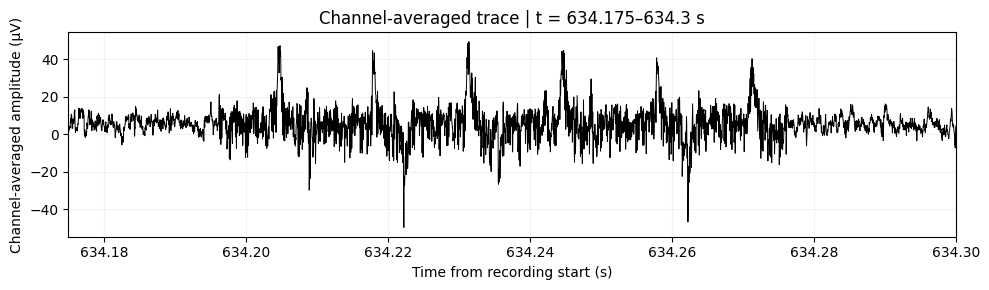

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import spikeinterface.full as si

# ══════════════════════════════════════════════════════════════
#  CONFIG – edit freely
# ══════════════════════════════════════════════════════════════
CFG = dict(
    bin_path    = "/nexus/posix0/MBR-neuralsystems/ephys/GLC7189/GLC7189_c_g0/GLC7189_c_g0_imec0/GLC7189_c_g0_t0.imec0.ap.bin",
    time_window = (634.175, 634.3),   # (t0, t1) seconds, absolute from recording start
    figsize     = (10, 3),          # (width, height) inches
    amp_scale   = 1.0,               # multiplier on the channel-averaged trace
    trace_color = "black",
    linewidth   = 0.7,
    save_path   = f"/u/gongt/lab_meeting_plots/channel_avg_trace_{CFG['time_window'][0]}_{CFG['time_window'][1]}.png",
    dpi         = 150,
)
# ══════════════════════════════════════════════════════════════


def plot_channel_average(cfg):
    bin_path = Path(cfg["bin_path"])
    folder = bin_path.parent   # spikeinterface reads the SpikeGLX folder, not the .bin directly

    print(f"Loading SpikeGLX recording from {folder}...")
    rec = si.read_spikeglx(folder, stream_id="imec0.ap")
    sr = rec.get_sampling_frequency()

    t0, t1 = cfg["time_window"]
    start_smp = int(t0 * sr)
    end_smp   = int(t1 * sr)

    print(f"Extracting traces for t=[{t0}, {t1}]s ...")
    traces = rec.get_traces(start_frame=start_smp, end_frame=end_smp, return_scaled=True)  # (n_samples, n_channels)

    chan_avg = traces.mean(axis=1) * cfg["amp_scale"]
    t_axis = np.linspace(t0, t1, traces.shape[0])   # absolute time, not window-relative

    fig, ax = plt.subplots(figsize=cfg["figsize"])
    ax.plot(t_axis, chan_avg, color=cfg["trace_color"], lw=cfg["linewidth"])

    ax.set_xlim(t0, t1)
    ax.set_xlabel("Time from recording start (s)")
    ax.set_ylabel("Channel-averaged amplitude (µV)")
    ax.set_title(f"Channel-averaged trace | t = {t0}–{t1} s")
    ax.grid(alpha=0.15)

    fig.tight_layout()
    fig.savefig(cfg["save_path"], dpi=cfg["dpi"])
    print(f"Saved: {cfg['save_path']}")
    return fig, ax


if __name__ == "__main__":
    plot_channel_average(CFG)